In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data if using CSV
df = pd.read_csv("../Ontrac_data.csv")

df.columns = df.columns.str.strip()

# Convert data types
df["Invoice_Date"] = pd.to_datetime(df["Invoice_Date"], errors="coerce")
df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce")

# Set visualization style
sns.set_theme(style="whitegrid")

# Check the data
print(df.head())
print(df.info())

  Invoice_Date               Client                      Products    Amount  \
0   2025-09-02              NOVAQUA      SIKACERAM 80I WHITE+GREY  21420.00   
1   2025-09-08   MY DE CONSTRUCTION           REBAR 08 TOR FE 500  11144.00   
2   2025-09-17          TERRASTRUCT  CEMENT CPJ35 (21 T +19 bags)  36790.00   
3   2025-09-22  STE DERRAB LISSAKAN    SIKACERAM 80I WHITE + GREY   4998.68   
4   2025-09-23  STE DERRAB LISSAKAN    WOOD TALK LOUVERS 200X1200   4999.60   

                      Bank_Document  
0                 TRANSFER RECEIVED  
1  COLLECTION OF 1 BILL OF EXCHANGE  
2                 TRANSFER RECEIVED  
3           OFF-BRANCH CASH DEPOSIT  
4           OFF-BRANCH CASH DEPOSIT  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147 entries, 0 to 146
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Invoice_Date   146 non-null    datetime64[ns]
 1   Client         147 non-null    obje

## 1. How does invoice value change over time?

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df["Invoice_Date"] = pd.to_datetime(df["Invoice_Date"])
df_1 = df.sort_values("Invoice_Date")

print(df_1[["Invoice_Date", "Amount"]])

    Invoice_Date    Amount
0     2025-09-02  21420.00
1     2025-09-08  11144.00
2     2025-09-17  36790.00
3     2025-09-22   4998.68
4     2025-09-23   4999.60
..           ...       ...
143   2026-08-24   3999.40
144   2026-08-24   3999.40
145   2026-08-28   3916.00
146   2026-08-28   4428.00
57           NaT   4999.68

[147 rows x 2 columns]


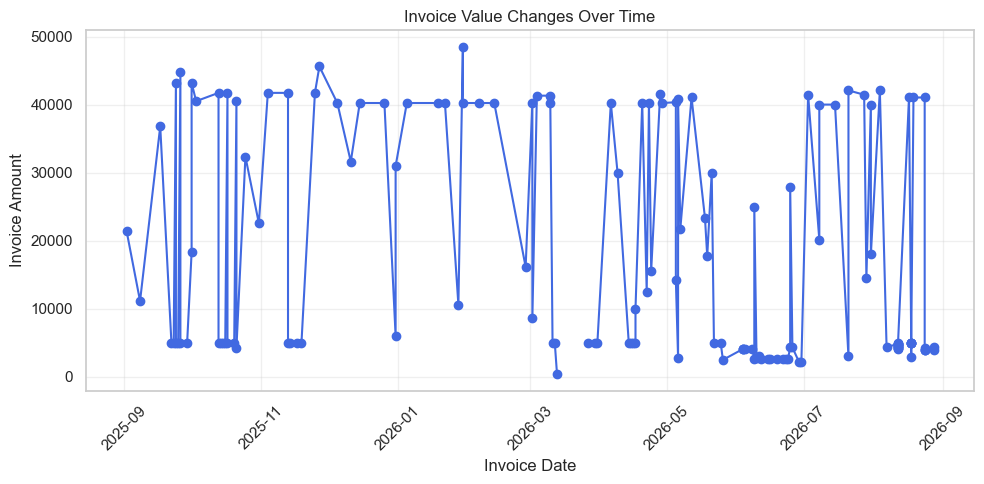

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    df["Invoice_Date"],
    df["Amount"],
    marker="o",
    color="royalblue"
)

plt.title("Invoice Value Changes Over Time")
plt.xlabel("Invoice Date")
plt.ylabel("Invoice Amount")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Which dates have unusually high-value invoices?

In [13]:
df

,Invoice_Date,Client,Products,Amount,Bank_Document
0,2025-09-02,NOVAQUA,SIKACERAM 80I WHITE+GREY,21420.00,TRANSFER RECEIVED
1,2025-09-08,MY DE CONSTRUCTION,REBAR 08 TOR FE 500,11144.00,COLLECTION OF 1 BILL OF EXCHANGE
2,2025-09-17,TERRASTRUCT,CEMENT CPJ35 (21 T +19 bags),36790.00,TRANSFER RECEIVED
3,2025-09-22,STE DERRAB LISSAKAN,SIKACERAM 80I WHITE + GREY,4998.68,OFF-BRANCH CASH DEPOSIT
4,2025-09-23,STE DERRAB LISSAKAN,WOOD TALK LOUVERS 200X1200,4999.60,OFF-BRANCH CASH DEPOSIT
...,...,...,...,...,...
142,2026-08-24,AYOUB MARRAKECH,WEBERCOL CLASSIC GREY,4254.48,OFF-BRANCH CASH DEPOSIT
143,2026-08-24,AYOUB MARRAKECH,WEBERCOL CLASSIC GREY,3999.40,OFF-BRANCH CASH DEPOSIT
144,2026-08-24,AYOUB MARRAKECH,WEBERCOL CLASSIC GREY,3999.40,OFF-BRANCH CASH DEPOSIT
145,2026-08-28,ISMANE DEVELOPPEMENT,WEBERCOL CLASSIC GREY,3916.00,OFF-BRANCH CASH DEPOSIT


In [15]:
Q1 = df["Amount"].quantile(0.25)
Q3 = df["Amount"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

high_invoices = df[df["Amount"] > upper_bound]

high_invoices[["Invoice_Date", "Client", "Amount"]]

,Invoice_Date,Client,Amount


np.float64(35679.28)